In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, f1_score

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from datasets import load_dataset

In [2]:
dataset = load_dataset("mteb/banking77")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (9993, 3)
Test shape: (3076, 3)


In [3]:
train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text        9993 non-null   str  
 1   label       9993 non-null   int64
 2   label_text  9993 non-null   str  
dtypes: int64(1), str(2)
memory usage: 1021.3 KB


In [5]:
train_df.isnull().sum()

text          0
label         0
label_text    0
dtype: int64

In [6]:
print("Number of classes:", train_df["label"].nunique())
print("Number of intents:", train_df["label_text"].nunique())

Number of classes: 77
Number of intents: 77


In [7]:
train_df["label_text"].value_counts()

label_text
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64

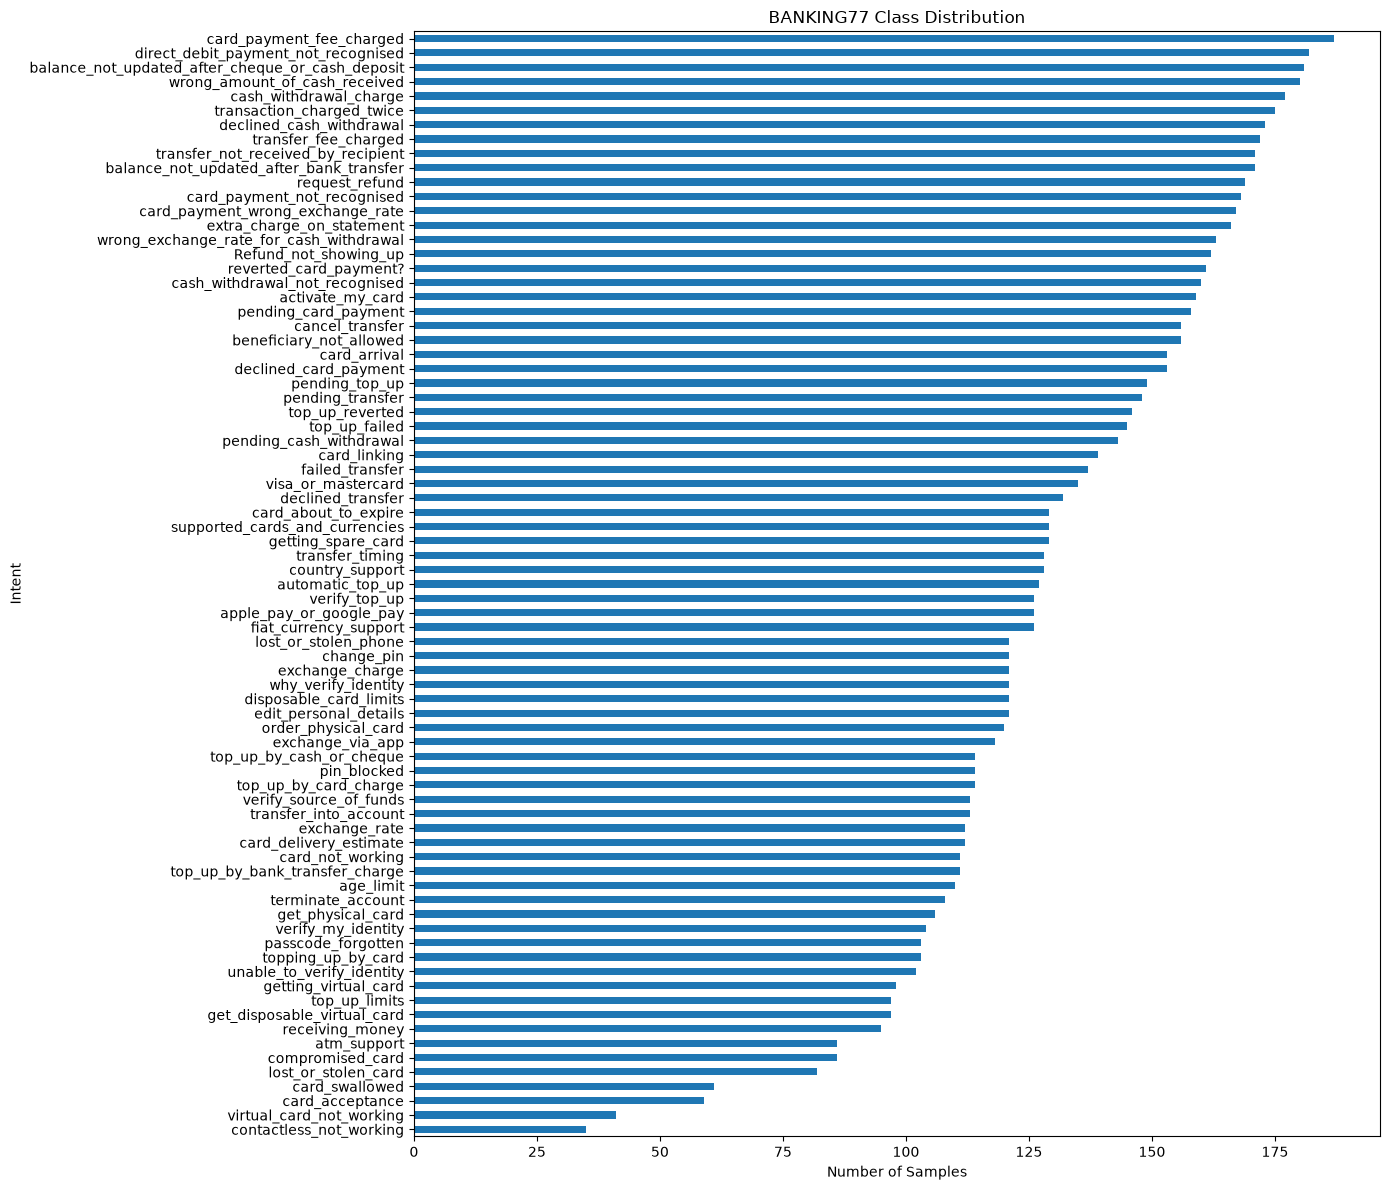

In [8]:
train_df["label_text"].value_counts().sort_values().plot(
    kind="barh",
    figsize=(14, 12)
)

plt.xlabel("Number of Samples")
plt.ylabel("Intent")
plt.title("BANKING77 Class Distribution")
plt.tight_layout()
plt.show()

In [9]:
print("Duplicate rows:", train_df.duplicated().sum())
print("Duplicate texts:", train_df["text"].duplicated().sum())

Duplicate rows: 0
Duplicate texts: 0


In [10]:
duplicate_texts = train_df[
    train_df["text"].duplicated(keep=False)
].sort_values("text")

duplicate_texts[["text", "label_text"]].head(30)

,text,label_text


In [11]:
conflicting_duplicates = (
    train_df.groupby("text")["label_text"]
    .nunique()
)

print(
    "Texts appearing with multiple labels:",
    (conflicting_duplicates > 1).sum()
)

Texts appearing with multiple labels: 0


In [12]:
train_df["char_count"] = train_df["text"].str.len()
train_df["word_count"] = train_df["text"].str.split().str.len()

In [13]:
train_df[["char_count", "word_count"]].describe()

,char_count,word_count
count,9993.000000,9993.000000
mean,59.501351,11.955369
std,40.873384,7.891187
min,13.000000,3.000000
25%,36.000000,7.000000
50%,47.000000,10.000000
75%,64.000000,13.000000
max,433.000000,79.000000


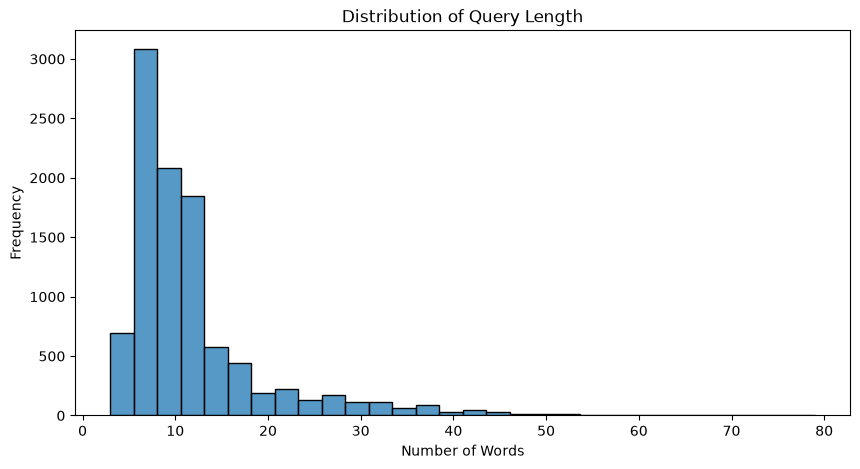

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["word_count"],
    bins=30
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Query Length")

plt.show()

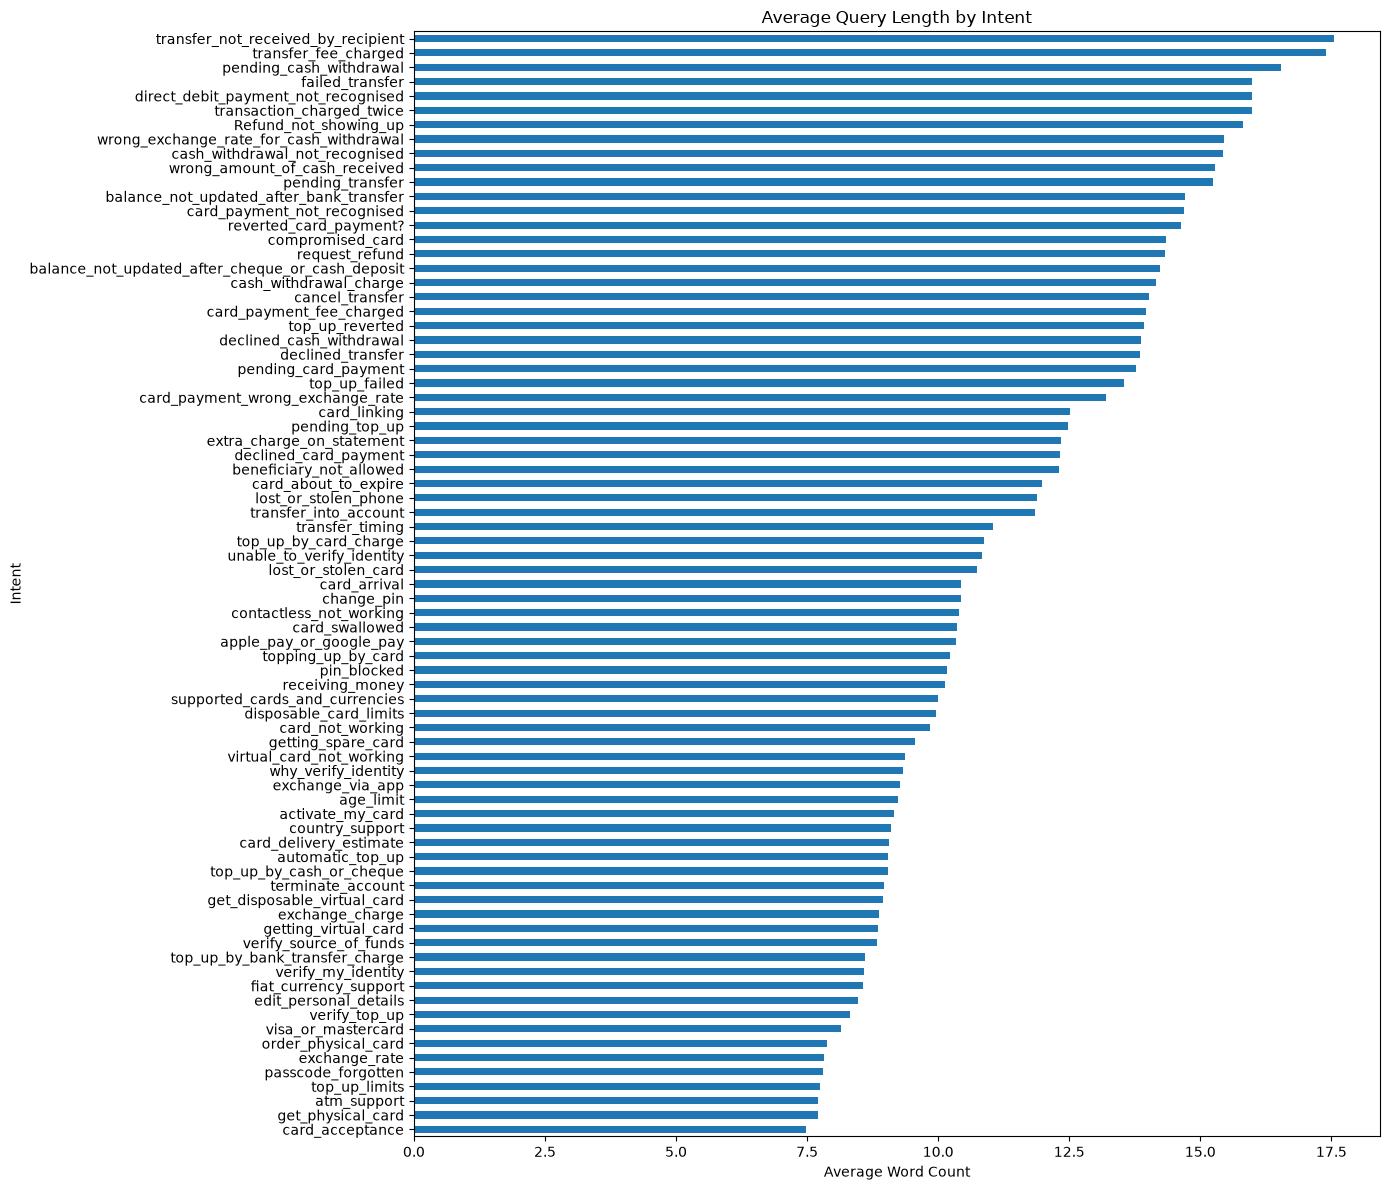

In [15]:
intent_length = (
    train_df.groupby("label_text")["word_count"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(14, 12))

intent_length.plot(kind="barh")

plt.xlabel("Average Word Count")
plt.ylabel("Intent")
plt.title("Average Query Length by Intent")

plt.tight_layout()
plt.show()


## 2. Prepare Data

In [16]:
X_train = train_df["text"]
y_train = train_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

In [17]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (9993,)
y_train: (9993,)
X_test: (3076,)
y_test: (3076,)


In [18]:
bow_vectorizer = CountVectorizer()

In [19]:
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

In [20]:
print("Training matrix shape:", X_train_bow.shape)
print("Testing matrix shape:", X_test_bow.shape)

Training matrix shape: (9993, 2319)
Testing matrix shape: (3076, 2319)


In [21]:
print("Vocabulary size:", len(bow_vectorizer.vocabulary_))

Vocabulary size: 2319


In [22]:
print(
    bow_vectorizer.get_feature_names_out()[:50]
)

['00' '000' '10' '100' '13' '16' '18' '1818' '1l' '20' '200' '2018' '30'
 '3d' '40' '45' '50' '500' '5x' '60' '80' 'able' 'about' 'above' 'abroad'
 'absolutely' 'accept' 'acceptable' 'accepted' 'accepting' 'accepts'
 'access' 'accessed' 'accessible' 'accessing' 'accident' 'accidentally'
 'accidently' 'accommodated' 'according' 'accordingly' 'account'
 'accounts' 'accurate' 'achieve' 'acount' 'acquiring' 'across' 'acting'
 'action']


In [23]:
lg_model_bow = LogisticRegression(max_iter=1000)

In [24]:
lg_model_bow.fit(X_train_bow, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [25]:
y_pred_bow = lg_model_bow.predict(X_test_bow)

In [26]:
accuracy_bow = accuracy_score(y_test, y_pred_bow)

print("BoW + Logistic Regression Accuracy:", accuracy_bow)

BoW + Logistic Regression Accuracy: 0.8907672301690507


In [27]:
print(
    classification_report(
        y_test,
        y_pred_bow,
        target_names=test_df["label_text"].unique()
    )
)

                                                  precision    recall  f1-score   support

                                    card_arrival       0.95      0.95      0.95        40
                                    card_linking       0.98      1.00      0.99        40
                                   exchange_rate       0.98      1.00      0.99        40
                card_payment_wrong_exchange_rate       0.92      0.92      0.92        39
                       extra_charge_on_statement       1.00      0.88      0.93        40
                         pending_cash_withdrawal       0.72      0.78      0.75        40
                           fiat_currency_support       0.86      0.95      0.90        40
                          card_delivery_estimate       0.95      0.90      0.92        40
                                automatic_top_up       0.95      0.95      0.95        40
                                card_not_working       0.95      1.00      0.98        40
         

In [28]:
tfidf_vectorizer = TfidfVectorizer()

In [29]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [30]:
print("Train matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

print(
    "Vocabulary size:",
    len(tfidf_vectorizer.vocabulary_)
)

Train matrix: (9993, 2319)
Test matrix: (3076, 2319)
Vocabulary size: 2319


In [31]:
lr_model_tfidf = LogisticRegression(max_iter=1000)

In [32]:
lr_model_tfidf.fit(X_train_tfidf,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [33]:
y_pred_tfidf = lr_model_tfidf.predict(X_test_tfidf)

In [34]:
accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)

print("TF-IDF + Logistic Regression Accuracy:", accuracy_tfidf)

TF-IDF + Logistic Regression Accuracy: 0.8777633289986996


In [35]:
print(
    classification_report(
        y_test,
        y_pred_tfidf,
        target_names=test_df["label_text"].unique()
    )
)

                                                  precision    recall  f1-score   support

                                    card_arrival       1.00      0.95      0.97        40
                                    card_linking       0.95      1.00      0.98        40
                                   exchange_rate       0.98      1.00      0.99        40
                card_payment_wrong_exchange_rate       0.97      0.90      0.93        39
                       extra_charge_on_statement       1.00      0.90      0.95        40
                         pending_cash_withdrawal       0.63      0.78      0.70        40
                           fiat_currency_support       0.84      0.95      0.89        40
                          card_delivery_estimate       0.94      0.85      0.89        40
                                automatic_top_up       0.95      0.95      0.95        40
                                card_not_working       0.95      1.00      0.98        40
         

In [36]:
print("BoW vocabulary size:",
      len(bow_vectorizer.vocabulary_))

print("TF-IDF vocabulary size:",
      len(tfidf_vectorizer.vocabulary_))

BoW vocabulary size: 2319
TF-IDF vocabulary size: 2319


In [37]:
tfidf_ngram = TfidfVectorizer(ngram_range=(1,2))

In [38]:
X_train_tfidf_ngram = tfidf_ngram.fit_transform(X_train)
X_test_tfidf_ngram = tfidf_ngram.transform(X_test)
print("Train shape:", X_train_tfidf_ngram.shape)
print("Test shape:", X_test_tfidf_ngram.shape)
print("Vocabulary size:", len(tfidf_ngram.vocabulary_))

Train shape: (9993, 23605)
Test shape: (3076, 23605)
Vocabulary size: 23605


In [39]:
lr_model_tfidf.fit(X_train_tfidf_ngram,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [40]:
y_pred_tfidf_ngram = lr_model_tfidf.predict(X_test_tfidf_ngram)

In [41]:
accuracy_tfidf_ngram = accuracy_score(y_test, y_pred_tfidf_ngram)

print("TF-IDF_ngram + Logistic Regression Accuracy:", accuracy_tfidf_ngram)

print(
    classification_report(
        y_test,
        y_pred_tfidf_ngram,
        target_names=test_df["label_text"].unique()
    )
)

TF-IDF_ngram + Logistic Regression Accuracy: 0.8553315994798439
                                                  precision    recall  f1-score   support

                                    card_arrival       1.00      0.93      0.96        40
                                    card_linking       1.00      1.00      1.00        40
                                   exchange_rate       0.98      1.00      0.99        40
                card_payment_wrong_exchange_rate       0.86      0.79      0.83        39
                       extra_charge_on_statement       1.00      0.90      0.95        40
                         pending_cash_withdrawal       0.65      0.80      0.72        40
                           fiat_currency_support       0.82      0.93      0.87        40
                          card_delivery_estimate       0.90      0.88      0.89        40
                                automatic_top_up       0.90      0.95      0.93        40
                                car

navie bayes + bow 

In [54]:
mnb_model_bow = MultinomialNB()

In [55]:
mnb_model_bow.fit(X_train_bow, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](77,)","[159.,110.,126.,...,121.,180.,163.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](77,)","[-4.14,-4.51,-4.37,...,-4.41,-4.02,-4.12]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](77,)","[ 0, 1, 2,...,74,75,76]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](77, 2319)","[[ 0., 0., 0.,..., 0., 0., 0.], [ 0., 0., 0.,..., 0., 0., 0.], [ 0., 0., 0.,..., 0., 0., 0.], ..., [ 0., 0., 0.,..., 0., 0., 0.], [ 2., 0.,11.,..., 0., 0., 0.], [ 0., 0., 0.,..., 0., 1., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](77, 2319)","[[-8.2 ,-8.2 ,-8.2 ,...,-8.2 ,-8.2 ,-8.2 ], [-8.1 ,-8.1 ,-8.1 ,...,-8.1 ,-8.1 ,-8.1 ], [-8.17,-8.17,-8.17,...,-8.17,-8.17,-8.17], ..., [-8.13,-8.13,-8.13,...,-8.13,-8.13,-8.13], [-7.37,-8.47,-5.99,...,-8.47,-8.47,-8.47], [-8.43,-8.43,-8.43,...,-8.43,-7.74,-8.43]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2319


In [56]:
mnb_pred_bow = mnb_model_bow.predict(X_test_bow)

In [57]:
accuracy_mnb_bow = accuracy_score(y_test, mnb_pred_bow)

print("Naive Bayes + BOW Accuracy:", accuracy_mnb_bow)

print(
    classification_report(
        y_test,
        mnb_pred_bow,
        target_names=test_df["label_text"].unique()
    )
)

Naive Bayes + BOW Accuracy: 0.7955136540962289
                                                  precision    recall  f1-score   support

                                    card_arrival       0.58      0.93      0.71        40
                                    card_linking       0.97      0.95      0.96        40
                                   exchange_rate       0.83      1.00      0.91        40
                card_payment_wrong_exchange_rate       0.89      0.64      0.75        39
                       extra_charge_on_statement       0.88      0.88      0.88        40
                         pending_cash_withdrawal       0.68      0.75      0.71        40
                           fiat_currency_support       0.77      0.93      0.84        40
                          card_delivery_estimate       0.75      0.82      0.79        40
                                automatic_top_up       0.86      0.93      0.89        40
                                card_not_working    

In [58]:
mnb_model_tfidf = MultinomialNB()
mnb_model_tfidf.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](77,)","[159.,110.,126.,...,121.,180.,163.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](77,)","[-4.14,-4.51,-4.37,...,-4.41,-4.02,-4.12]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](77,)","[ 0, 1, 2,...,74,75,76]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](77, 2319)","[[0. ,0. ,0. ,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,0. ], ..., [0. ,0. ,0. ,...,0. ,0. ,0. ], [1.04,0. ,2.77,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0.27,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](77, 2319)","[[-7.91,-7.91,-7.91,...,-7.91,-7.91,-7.91], [-7.87,-7.87,-7.87,...,-7.87,-7.87,-7.87], [-7.89,-7.89,-7.89,...,-7.89,-7.89,-7.89], ..., [-7.88,-7.88,-7.88,...,-7.88,-7.88,-7.88], [-7.26,-7.97,-6.64,...,-7.97,-7.97,-7.97], [-7.96,-7.96,-7.96,...,-7.96,-7.72,-7.96]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2319


In [59]:
mnb_pred_tfidf = mnb_model_tfidf.predict(X_test_tfidf)

In [60]:
accuracy_mnb_tfidf = accuracy_score(y_test, mnb_pred_tfidf)

print("TF-IDF + Multinominal Navie bayes Accuracy:", accuracy_mnb_tfidf)

print(
    classification_report(
        y_test,
        mnb_pred_tfidf,
        target_names=test_df["label_text"].unique()
    )
)

TF-IDF + Multinominal Navie bayes Accuracy: 0.7877113133940182
                                                  precision    recall  f1-score   support

                                    card_arrival       0.63      0.95      0.76        40
                                    card_linking       1.00      0.95      0.97        40
                                   exchange_rate       0.82      1.00      0.90        40
                card_payment_wrong_exchange_rate       0.88      0.56      0.69        39
                       extra_charge_on_statement       0.92      0.90      0.91        40
                         pending_cash_withdrawal       0.60      0.78      0.67        40
                           fiat_currency_support       0.69      0.93      0.79        40
                          card_delivery_estimate       0.81      0.88      0.84        40
                                automatic_top_up       0.93      0.97      0.95        40
                                card

f:\Python&machinelearning\project\NLP\CustomerSupportticket\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
f:\Python&machinelearning\project\NLP\CustomerSupportticket\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
f:\Python&machinelearning\project\NLP\CustomerSupportticket\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to contr

SVM + Bow + tfidf

In [64]:
svm_model_bow = LinearSVC( C=1.0,
    max_iter=3000,
    random_state=42)

In [65]:
svm_model_bow.fit(X_train_bow,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",3000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are su

In [66]:
svm_pred_bow = svm_model_bow.predict(X_test_bow)

In [67]:
accuracy_svm_bow = accuracy_score(y_test, svm_pred_bow)

print("Bag of Words + SVM Accuracy:", accuracy_svm_bow)

print(
    classification_report(
        y_test,
        svm_pred_bow,
        target_names=test_df["label_text"].unique()
    )
)

Bag of Words + SVM Accuracy: 0.8875162548764629
                                                  precision    recall  f1-score   support

                                    card_arrival       0.95      0.97      0.96        40
                                    card_linking       0.98      1.00      0.99        40
                                   exchange_rate       0.98      1.00      0.99        40
                card_payment_wrong_exchange_rate       0.83      0.90      0.86        39
                       extra_charge_on_statement       0.97      0.90      0.94        40
                         pending_cash_withdrawal       0.66      0.72      0.69        40
                           fiat_currency_support       0.95      0.90      0.92        40
                          card_delivery_estimate       0.95      0.93      0.94        40
                                automatic_top_up       0.95      0.88      0.91        40
                                card_not_working   

In [68]:
svm_model_tfidf = LinearSVC(
    C = 1.0,
    max_iter = 3000,
    random_state = 42
    )

In [69]:
svm_model_tfidf.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",3000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are su

In [71]:
svm_pred_tfidf = svm_model_tfidf.predict(X_test_tfidf)

In [72]:
accuracy_svm_tfidf = accuracy_score(y_test, svm_pred_tfidf)

print("TF-IDF + SVM Accuracy:", accuracy_svm_tfidf)

print(
    classification_report(
        y_test,
        svm_pred_tfidf,
        target_names=test_df["label_text"].unique()
    )
)

TF-IDF + SVM Accuracy: 0.8946684005201561
                                                  precision    recall  f1-score   support

                                    card_arrival       0.97      0.97      0.97        40
                                    card_linking       0.95      1.00      0.98        40
                                   exchange_rate       0.98      1.00      0.99        40
                card_payment_wrong_exchange_rate       0.90      0.97      0.94        39
                       extra_charge_on_statement       0.95      0.97      0.96        40
                         pending_cash_withdrawal       0.67      0.78      0.72        40
                           fiat_currency_support       0.93      0.95      0.94        40
                          card_delivery_estimate       0.97      0.88      0.92        40
                                automatic_top_up       0.97      0.95      0.96        40
                                card_not_working       0.

In [73]:
for c in [0.1, 0.5, 1.0, 2.0, 5.0]:
    model = LinearSVC(C=c, max_iter=5000, random_state=42)
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, predictions)

    print(f"C = {c}: Accuracy = {accuracy:.4f}")

C = 0.1: Accuracy = 0.8657
C = 0.5: Accuracy = 0.8914
C = 1.0: Accuracy = 0.8947
C = 2.0: Accuracy = 0.8924
C = 5.0: Accuracy = 0.8852


In [75]:
label_mapping = (
    train_df[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
)

print(label_mapping.head())
print("Total classes:", len(label_mapping))

      label               label_text
9170      0         activate_my_card
1556      1                age_limit
9635      2  apple_pay_or_google_pay
4542      3              atm_support
1118      4         automatic_top_up
Total classes: 77


In [76]:
best_svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

best_svm.fit(X_train_tfidf, y_train)

y_pred_best_svm = best_svm.predict(X_test_tfidf)

print(classification_report(
    y_test,
    y_pred_best_svm,
    labels=label_mapping["label"].tolist(),
    target_names=label_mapping["label_text"].tolist(),
    zero_division=0
))

                                                  precision    recall  f1-score   support

                                activate_my_card       0.97      0.97      0.97        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       0.98      1.00      0.99        40
                                     atm_support       0.90      0.97      0.94        39
                                automatic_top_up       0.95      0.97      0.96        40
         balance_not_updated_after_bank_transfer       0.67      0.78      0.72        40
balance_not_updated_after_cheque_or_cash_deposit       0.93      0.95      0.94        40
                         beneficiary_not_allowed       0.97      0.88      0.92        40
                                 cancel_transfer       0.97      0.95      0.96        40
                            card_about_to_expire       0.97      0.97      0.97        40
         

In [77]:
import pandas as pd

error_df = pd.DataFrame({
    "text": test_df["text"].values,
    "actual": test_df["label_text"].values,
    "predicted": label_mapping.set_index("label")
        .loc[y_pred_best_svm, "label_text"].values
})

error_df = error_df[error_df["actual"] != error_df["predicted"]]

print("Total incorrect predictions:", len(error_df))
print(error_df.head(15).to_string(index=False))

Total incorrect predictions: 324
                                                                                text                           actual                               predicted
                                                            How do I locate my card?                     card_arrival                       get_physical_card
                                                            When will I get my card?                     card_arrival                  card_delivery_estimate
                                                 How long does a card delivery take?                     card_arrival                  card_delivery_estimate
                                              I did not get my card yet, is it lost?                     card_arrival                     lost_or_stolen_card
                                             How do I know when my card will arrive?                     card_arrival                  card_delivery_estimate
I'm starting to thi

In [80]:


cm = confusion_matrix(
    y_test,
    y_pred_best_svm,
    labels=label_mapping["label"].tolist()
)

cm_df = pd.DataFrame(
    cm,
    index=label_mapping["label_text"],
    columns=label_mapping["label_text"]
)

# Remove correct predictions from the diagonal
for intent in cm_df.index:
    cm_df.loc[intent, intent] = 0

# Find the 15 most frequent confusion pairs
confusion_pairs = (
    cm_df.stack()
    .sort_values(ascending=False)
    .head(15)
)

print(confusion_pairs)

label_text                               label_text                             
pending_transfer                         balance_not_updated_after_bank_transfer    5
virtual_card_not_working                 get_disposable_virtual_card                5
why_verify_identity                      unable_to_verify_identity                  5
fiat_currency_support                    exchange_via_app                           4
balance_not_updated_after_bank_transfer  pending_transfer                           4
fiat_currency_support                    supported_cards_and_currencies             4
top_up_reverted                          top_up_failed                              4
unable_to_verify_identity                verify_my_identity                         4
why_verify_identity                      verify_my_identity                         4
card_arrival                             card_delivery_estimate                     3
disposable_card_limits                   getting_virtual_ca

In [81]:
pairs = [
    ("pending_transfer", "balance_not_updated_after_bank_transfer"),
    ("virtual_card_not_working", "get_disposable_virtual_card"),
    ("why_verify_identity", "unable_to_verify_identity"),
]

for actual_intent, predicted_intent in pairs:
    print(f"\n{'=' * 70}")
    print(f"Actual: {actual_intent}")
    print(f"Predicted: {predicted_intent}")

    examples = error_df[
        (error_df["actual"] == actual_intent) &
        (error_df["predicted"] == predicted_intent)
    ]

    for _, row in examples.iterrows():
        print(f"\nText: {row['text']}")
        


Actual: pending_transfer
Predicted: balance_not_updated_after_bank_transfer

Text: I transferred money yesterday, but it still isn't available?

Text: How long do transfer pend for?

Text: Someone transferred money to me and it doesn't show

Text: I made a transfer 12 hours ago. Why is it still listed as pending?

Text: Why is a money transfer not showing?

Actual: virtual_card_not_working
Predicted: get_disposable_virtual_card

Text: Why is my disposable virtual card being denied?

Text: My disposable virtual card is broken.

Text: Is there a trick to get the disposable virtual card to work?

Text: My transaction was just declined when I was using my disposable virtual card. What can I do?

Text: How do I get my disposable virtual card to work?

Actual: why_verify_identity
Predicted: unable_to_verify_identity

Text: I'd rather not verify my identity.

Text: I would like to not have to do the identity verification.

Text: Since my id hasn't been verified, when can I use my account?

T

In [83]:
tfidf_sublinear = TfidfVectorizer(sublinear_tf=True)

X_train_sublinear = tfidf_sublinear.fit_transform(X_train)
X_test_sublinear = tfidf_sublinear.transform(X_test)

svm_sublinear = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

svm_sublinear.fit(X_train_sublinear, y_train)

pred_sublinear = svm_sublinear.predict(X_test_sublinear)

print("Accuracy:", accuracy_score(y_test, pred_sublinear))
print("Macro F1:", f1_score(y_test, pred_sublinear, average="macro"))

Accuracy: 0.8949934980494149
Macro F1: 0.8948727912919241


In [85]:
from sklearn.pipeline import FeatureUnion

combined_tfidf = FeatureUnion([
    ("word", TfidfVectorizer(
        sublinear_tf=True,
        ngram_range=(1, 2)
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True
    ))
])

X_train_combined = combined_tfidf.fit_transform(X_train)
X_test_combined = combined_tfidf.transform(X_test)

combined_svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

combined_svm.fit(X_train_combined, y_train)
pred_combined = combined_svm.predict(X_test_combined)

print("Accuracy:", accuracy_score(y_test, pred_combined))
print("Macro F1:", f1_score(y_test, pred_combined, average="macro"))

Accuracy: 0.9099479843953185
Macro F1: 0.9099208921817976


In [ ]:

print(classification_report(
    y_test,
    pred_combined,
    labels=label_mapping["label"].tolist(),
    target_names=label_mapping["label_text"].tolist(),
    zero_division=0
))


                                                  precision    recall  f1-score   support

                                activate_my_card       0.97      0.97      0.97        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.93      0.97      0.95        39
                                automatic_top_up       0.98      1.00      0.99        40
         balance_not_updated_after_bank_transfer       0.78      0.80      0.79        40
balance_not_updated_after_cheque_or_cash_deposit       0.95      0.95      0.95        40
                         beneficiary_not_allowed       0.97      0.95      0.96        40
                                 cancel_transfer       1.00      0.95      0.97        40
                            card_about_to_expire       1.00      0.97      0.99        40
         

In [87]:

cm_combined = confusion_matrix(
    y_test,
    pred_combined,
    labels=label_mapping["label"].tolist()
)

cm_combined_df = pd.DataFrame(
    cm_combined,
    index=label_mapping["label_text"],
    columns=label_mapping["label_text"]
)

pairs = [
    ("pending_transfer", "balance_not_updated_after_bank_transfer"),
    ("virtual_card_not_working", "get_disposable_virtual_card"),
    ("why_verify_identity", "unable_to_verify_identity"),
    ("card_arrival", "card_delivery_estimate"),
]

for actual, predicted in pairs:
    print(
        f"{actual} -> {predicted}: "
        f"{cm_combined_df.loc[actual, predicted]}"
    )

pending_transfer -> balance_not_updated_after_bank_transfer: 1
virtual_card_not_working -> get_disposable_virtual_card: 1
why_verify_identity -> unable_to_verify_identity: 4
card_arrival -> card_delivery_estimate: 3
